## 1. General Imports

In [29]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import os 
import glob

## 2. Creating the merged dataset

In [30]:
base_url = "../../results/Splined/TwoDepths/"
variables = ["A%","CE","CEC","L%","OM(%)","pH","S%"]
csv_files = sorted(glob.glob(os.path.join(base_url, "*.csv")))

dfs=[]

for index  , (file , var) in enumerate(zip(os.listdir(f"{base_url}") , variables)):
    df = pd.DataFrame()
    df_file = pd.read_csv(f"{base_url}/{file}")
    df["SID"] = df_file["SID"]
    df["UD"] = df_file["UD"]
    df["LD"]= df_file["LD"]
    df[var] = df_file["SPLINED_VALUE"]
    print(len(df.drop_duplicates(subset="SID")))
    dfs.append(df)



2058
1031
2051
2052
380
2111
2091


In [31]:
dfs[6]

,SID,UD,LD,S%
0,-0.0002541362021_35.83417876,0,30,79.410878
1,-0.0002541362021_35.83417876,30,120,80.333011
2,-0.0003898600894_35.83778028,0,30,71.168573
3,-0.0003898600894_35.83778028,30,120,70.857100
4,-0.003494819662_35.81572507,0,30,86.647367
...,...,...,...,...
3573,8.2_36.9,30,120,58.275175
3574,8.341388889_36.90027778,0,30,68.632676
3575,8.341388889_36.90027778,30,120,65.536329
3576,8.386666667_37.06444444,0,30,62.606783


In [32]:
print(dfs[1].value_counts())

SID                           UD  LD   CE        
-0.0002541362021_35.83417876  0   30   3.176410      1
0.4746665593_30.53008399      0   30   0.872663      1
0.4805832728_30.53958397      0   30   1.294756      1
0.4790277334_30.53580621      30  120  0.318684      1
                              0   30   1.197500      1
                                                    ..
0.012744125_35.84171269       0   30   6.014125      1
0.0126089512_35.84531424      30  120  3.533943      1
                              0   30   3.639396      1
0.01007852446_35.79478227     0   30   4.190000      1
7.809722222_36.78055556       0   30   274.000000    1
Name: count, Length: 1883, dtype: int64


In [33]:
len(dfs)

7

In [34]:
merged_df = pd.merge(dfs[0], dfs[1], on=['SID',"UD","LD"], how='outer')
merged_df = pd.merge(merged_df, dfs[2], on=['SID',"UD","LD"], how='outer')
merged_df = pd.merge(merged_df, dfs[3], on=['SID',"UD","LD"], how='outer')
merged_df = pd.merge(merged_df, dfs[4], on=['SID',"UD","LD"], how='outer')
merged_df = pd.merge(merged_df, dfs[5], on=['SID',"UD","LD"], how='outer')
df = pd.merge(merged_df, dfs[6], on=['SID',"UD","LD"], how='outer')
df

,SID,UD,LD,A%,CE,CEC,L%,OM(%),pH,S%
0,-0.0002541362021_35.83417876,0,30,3.874832,3.176410,0.320644,16.714290,NaN,7.581977,79.410878
1,-0.0002541362021_35.83417876,30,120,3.063295,3.061943,0.373544,16.603694,NaN,7.686836,80.333011
2,-0.0003898600894_35.83778028,0,30,3.668154,3.948343,0.271090,25.163273,NaN,7.206384,71.168573
3,-0.0003898600894_35.83778028,30,120,4.370591,5.053459,0.364238,24.772308,NaN,7.729494,70.857100
4,-0.003494819662_35.81572507,0,30,0.980614,1.677930,0.317694,12.372019,NaN,7.770263,86.647367
...,...,...,...,...,...,...,...,...,...,...
3684,8.2_36.9,30,120,5.510425,NaN,0.100393,36.214400,70.372344,4.782108,58.275175
3685,8.341388889_36.90027778,0,30,6.147587,NaN,0.100000,25.219737,22.523778,6.221084,68.632676
3686,8.341388889_36.90027778,30,120,6.175356,NaN,0.100000,28.288315,28.467973,6.331700,65.536329
3687,8.386666667_37.06444444,0,30,13.239788,NaN,0.100000,24.153271,46.935964,5.154586,62.606783


In [35]:
df[['X', 'Y']] = df['SID'].str.split('_', expand=True)
df['X'] = pd.to_numeric(df['X'])
df['Y'] = pd.to_numeric(df['Y'])
df

,SID,UD,LD,A%,CE,CEC,L%,OM(%),pH,S%,X,Y
0,-0.0002541362021_35.83417876,0,30,3.874832,3.176410,0.320644,16.714290,NaN,7.581977,79.410878,-0.000254,35.834179
1,-0.0002541362021_35.83417876,30,120,3.063295,3.061943,0.373544,16.603694,NaN,7.686836,80.333011,-0.000254,35.834179
2,-0.0003898600894_35.83778028,0,30,3.668154,3.948343,0.271090,25.163273,NaN,7.206384,71.168573,-0.000390,35.837780
3,-0.0003898600894_35.83778028,30,120,4.370591,5.053459,0.364238,24.772308,NaN,7.729494,70.857100,-0.000390,35.837780
4,-0.003494819662_35.81572507,0,30,0.980614,1.677930,0.317694,12.372019,NaN,7.770263,86.647367,-0.003495,35.815725
...,...,...,...,...,...,...,...,...,...,...,...,...
3684,8.2_36.9,30,120,5.510425,NaN,0.100393,36.214400,70.372344,4.782108,58.275175,8.200000,36.900000
3685,8.341388889_36.90027778,0,30,6.147587,NaN,0.100000,25.219737,22.523778,6.221084,68.632676,8.341389,36.900278
3686,8.341388889_36.90027778,30,120,6.175356,NaN,0.100000,28.288315,28.467973,6.331700,65.536329,8.341389,36.900278
3687,8.386666667_37.06444444,0,30,13.239788,NaN,0.100000,24.153271,46.935964,5.154586,62.606783,8.386667,37.064444


In [36]:
df.drop_duplicates(subset=["X","Y"])

,SID,UD,LD,A%,CE,CEC,L%,OM(%),pH,S%,X,Y
0,-0.0002541362021_35.83417876,0,30,3.874832,3.176410,0.320644,16.714290,NaN,7.581977,79.410878,-0.000254,35.834179
2,-0.0003898600894_35.83778028,0,30,3.668154,3.948343,0.271090,25.163273,NaN,7.206384,71.168573,-0.000390,35.837780
4,-0.003494819662_35.81572507,0,30,0.980614,1.677930,0.317694,12.372019,NaN,7.770263,86.647367,-0.003495,35.815725
6,-0.003630258252_35.81212353,0,30,5.316877,3.836355,0.320034,14.397284,NaN,8.049828,80.285839,-0.003630,35.812124
8,-0.003765672812_35.80852198,0,30,3.284772,4.608883,0.322710,162.925590,NaN,7.499265,71.125719,-0.003766,35.808522
...,...,...,...,...,...,...,...,...,...,...,...,...
3680,7.809722222_36.78055556,0,30,48.000000,274.000000,0.250000,24.400000,NaN,8.270000,22.050000,7.809722,36.780556
3681,7.9925_36.84861111,0,30,4.620103,NaN,0.119979,27.112725,79.074556,5.598996,68.267171,7.992500,36.848611
3683,8.2_36.9,0,30,3.893451,NaN,0.099874,40.802534,61.363843,5.451622,55.304015,8.200000,36.900000
3685,8.341388889_36.90027778,0,30,6.147587,NaN,0.100000,25.219737,22.523778,6.221084,68.632676,8.341389,36.900278


## 3.oredering the columns

In [37]:
df = df[["SID" ,"X","Y","UD","LD","pH","CE","CEC","A%","L%","S%","OM(%)"]]
df

,SID,X,Y,UD,LD,pH,CE,CEC,A%,L%,S%,OM(%)
0,-0.0002541362021_35.83417876,-0.000254,35.834179,0,30,7.581977,3.176410,0.320644,3.874832,16.714290,79.410878,NaN
1,-0.0002541362021_35.83417876,-0.000254,35.834179,30,120,7.686836,3.061943,0.373544,3.063295,16.603694,80.333011,NaN
2,-0.0003898600894_35.83778028,-0.000390,35.837780,0,30,7.206384,3.948343,0.271090,3.668154,25.163273,71.168573,NaN
3,-0.0003898600894_35.83778028,-0.000390,35.837780,30,120,7.729494,5.053459,0.364238,4.370591,24.772308,70.857100,NaN
4,-0.003494819662_35.81572507,-0.003495,35.815725,0,30,7.770263,1.677930,0.317694,0.980614,12.372019,86.647367,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
3684,8.2_36.9,8.200000,36.900000,30,120,4.782108,NaN,0.100393,5.510425,36.214400,58.275175,70.372344
3685,8.341388889_36.90027778,8.341389,36.900278,0,30,6.221084,NaN,0.100000,6.147587,25.219737,68.632676,22.523778
3686,8.341388889_36.90027778,8.341389,36.900278,30,120,6.331700,NaN,0.100000,6.175356,28.288315,65.536329,28.467973
3687,8.386666667_37.06444444,8.386667,37.064444,0,30,5.154586,NaN,0.100000,13.239788,24.153271,62.606783,46.935964


In [38]:
print(df.isna().sum())

SID         0
X           0
Y           0
UD          0
LD          0
pH         92
CE       1806
CEC       206
A%        148
L%        163
S%        111
OM(%)    3010
dtype: int64


In [39]:
ud_counts = df['UD'].value_counts()
ld_counts = df['LD'].value_counts()

print(ud_counts , ld_counts)

UD
0     2146
30    1543
Name: count, dtype: int64 LD
30     2146
120    1543
Name: count, dtype: int64


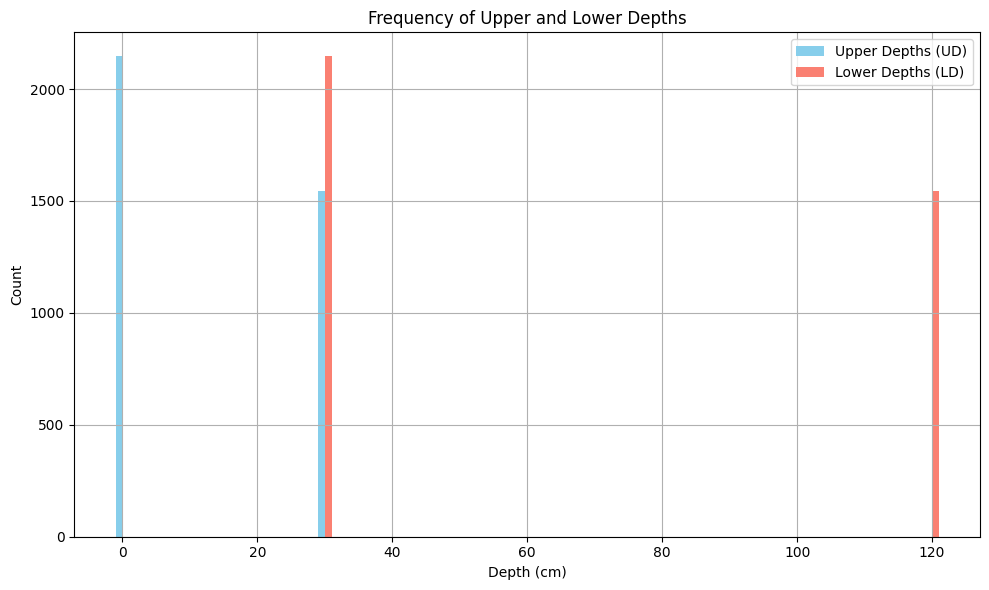

In [40]:
ud_counts = df['UD'].value_counts().sort_index()
ld_counts = df['LD'].value_counts().sort_index()
plt.figure(figsize=(10, 6))
plt.bar(ud_counts.index - 0.5, ud_counts.values, width=1.0, color='skyblue', label='Upper Depths (UD)')
plt.bar(ld_counts.index + 0.5, ld_counts.values, width=1.0, color='salmon', label='Lower Depths (LD)')

plt.xlabel('Depth (cm)')
plt.ylabel('Count')
plt.title('Frequency of Upper and Lower Depths')
plt.legend()
plt.grid(True)
plt.tight_layout()

## 4. Add all unadded depths ranges

In [41]:
standard_depths = [(0, 30),(30, 120)]
unique_coords = df[['X', 'Y']].drop_duplicates()
full_rows = []
for _, row in unique_coords.iterrows():
    x, y = row['X'], row['Y']
    for ud, ld in standard_depths:
        full_rows.append({'X': x, 'Y': y, 'UD': ud, 'LD': ld})
full_df = pd.DataFrame(full_rows)
merged_df = pd.merge(full_df, df, on=['X', 'Y', 'UD', 'LD'], how='left')
merged_df['SID'] = merged_df['X'].astype(str) + "_" + merged_df['Y'].astype(str)
cols = ['SID', 'X', 'Y', 'UD', 'LD'] + [col for col in merged_df.columns if col not in ['SID', 'X', 'Y', 'UD', 'LD']]
merged_df = merged_df[cols]

merged_df

,SID,X,Y,UD,LD,pH,CE,CEC,A%,L%,S%,OM(%)
0,-0.0002541362021_35.83417876,-0.000254,35.834179,0,30,7.581977,3.176410,0.320644,3.874832,16.714290,79.410878,NaN
1,-0.0002541362021_35.83417876,-0.000254,35.834179,30,120,7.686836,3.061943,0.373544,3.063295,16.603694,80.333011,NaN
2,-0.0003898600894_35.83778028,-0.000390,35.837780,0,30,7.206384,3.948343,0.271090,3.668154,25.163273,71.168573,NaN
3,-0.0003898600894_35.83778028,-0.000390,35.837780,30,120,7.729494,5.053459,0.364238,4.370591,24.772308,70.857100,NaN
4,-0.003494819662_35.81572507,-0.003495,35.815725,0,30,7.770263,1.677930,0.317694,0.980614,12.372019,86.647367,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
4309,8.2_36.9,8.200000,36.900000,30,120,4.782108,NaN,0.100393,5.510425,36.214400,58.275175,70.372344
4310,8.341388889_36.90027778,8.341389,36.900278,0,30,6.221084,NaN,0.100000,6.147587,25.219737,68.632676,22.523778
4311,8.341388889_36.90027778,8.341389,36.900278,30,120,6.331700,NaN,0.100000,6.175356,28.288315,65.536329,28.467973
4312,8.386666667_37.06444444,8.386667,37.064444,0,30,5.154586,NaN,0.100000,13.239788,24.153271,62.606783,46.935964


In [42]:
merged_df.to_csv("../../results/Soil/full_splined2.csv")

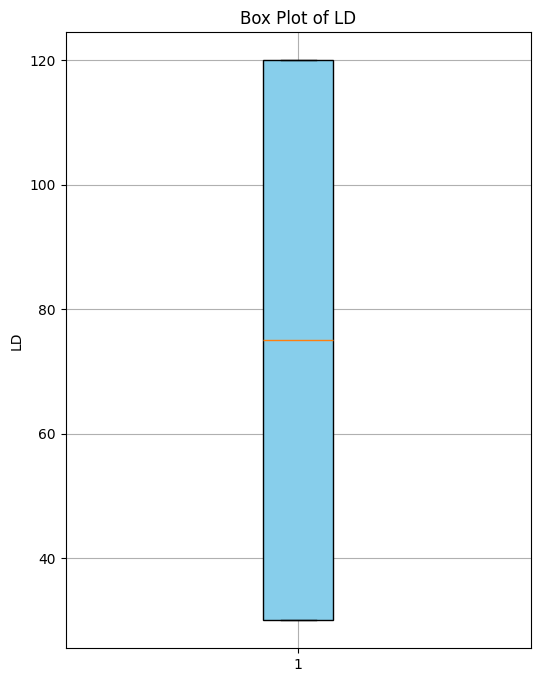

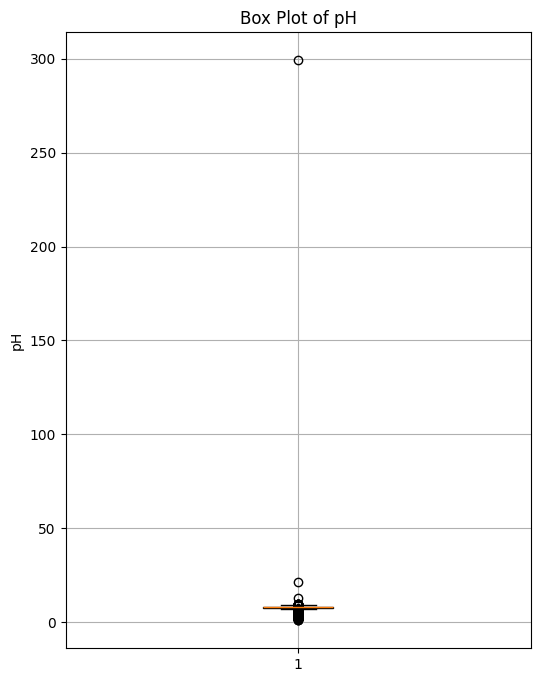

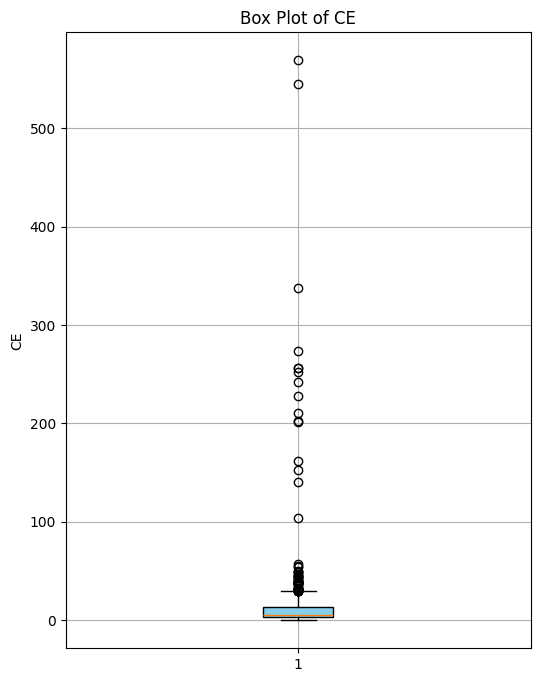

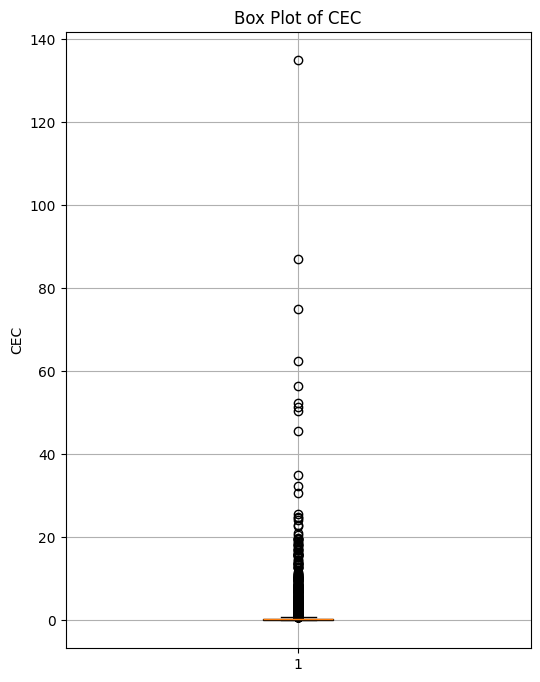

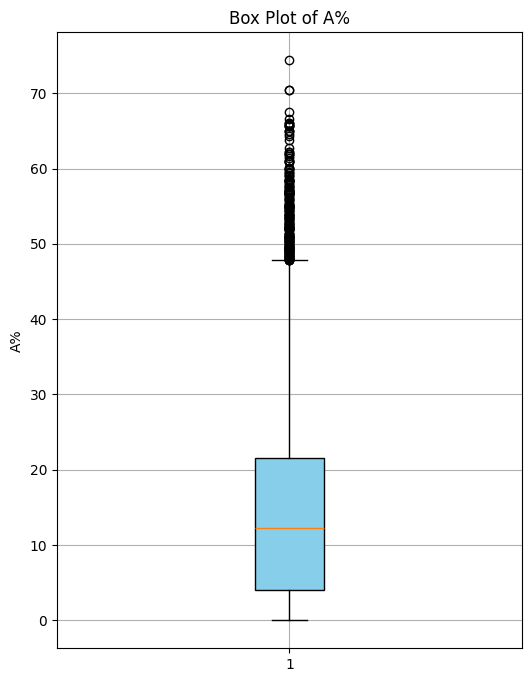

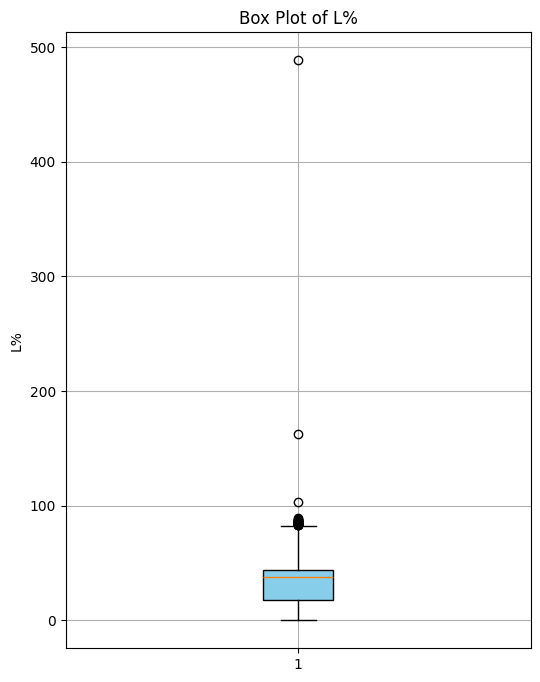

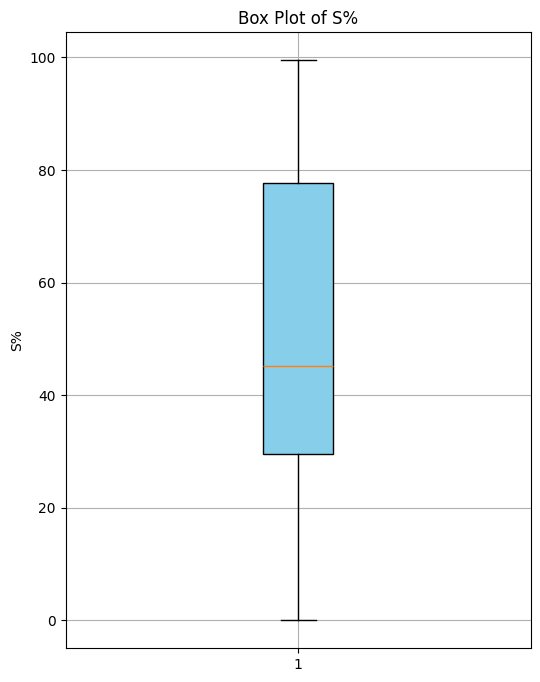

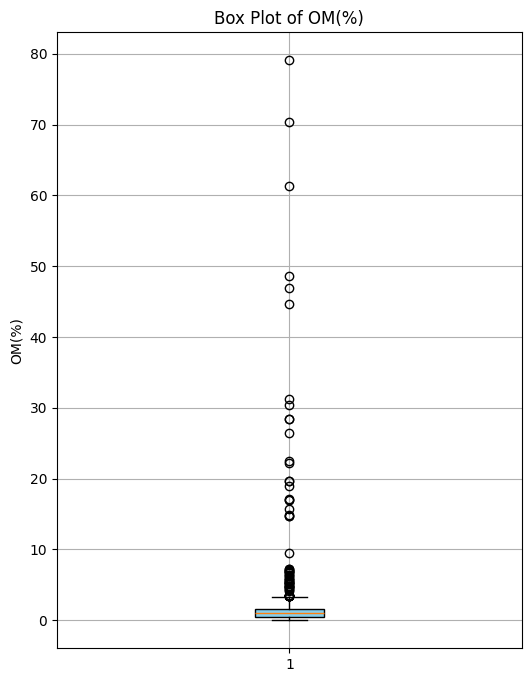

In [43]:
for i in merged_df.columns[4:]:
    plt.figure(figsize=(6, 8))
    plt.boxplot(merged_df[i].dropna(), vert=True, patch_artist=True, boxprops=dict(facecolor='skyblue'))

    plt.ylabel(i)
    plt.title(f'Box Plot of {i}')

    # Show the plot
    plt.grid(True)
    plt.show()

## 5. Treating the missing values

In [44]:
import pandas as pd
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

numeric_df = merged_df.select_dtypes(include=['float64', 'int64'])
scaler = StandardScaler()
scaled_data = scaler.fit_transform(numeric_df)

imputer = KNNImputer(n_neighbors=5)
imputed_array = imputer.fit_transform(scaled_data)
real_values = scaler.inverse_transform(imputed_array)
merged_df[numeric_df.columns] = real_values
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4314 entries, 0 to 4313
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SID     4314 non-null   object 
 1   X       4314 non-null   float64
 2   Y       4314 non-null   float64
 3   UD      4314 non-null   float64
 4   LD      4314 non-null   float64
 5   pH      4314 non-null   float64
 6   CE      4314 non-null   float64
 7   CEC     4314 non-null   float64
 8   A%      4314 non-null   float64
 9   L%      4314 non-null   float64
 10  S%      4314 non-null   float64
 11  OM(%)   4314 non-null   float64
dtypes: float64(11), object(1)
memory usage: 404.6+ KB


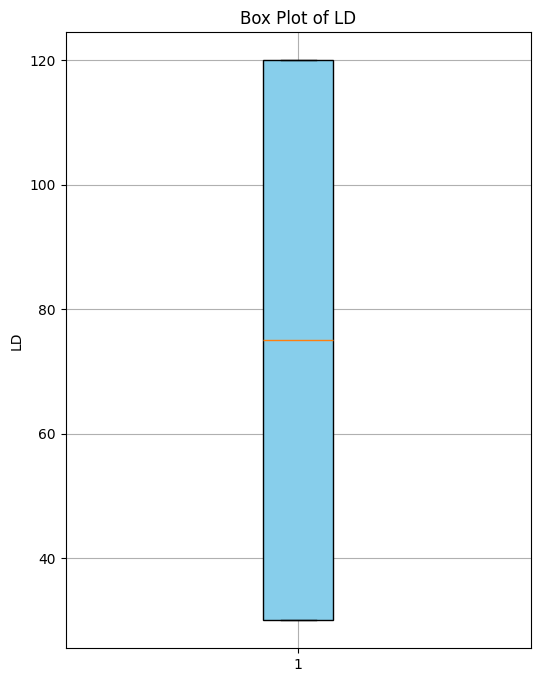

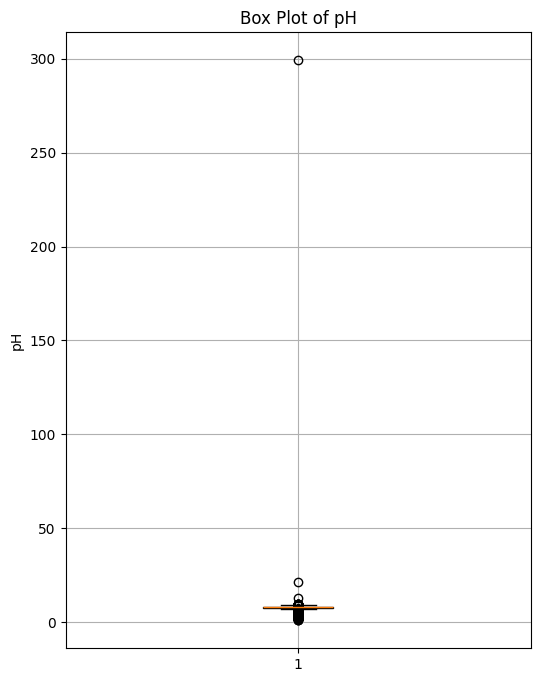

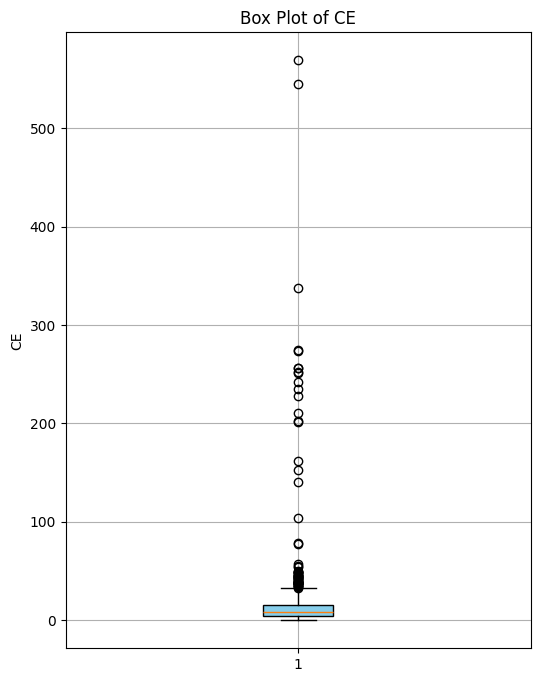

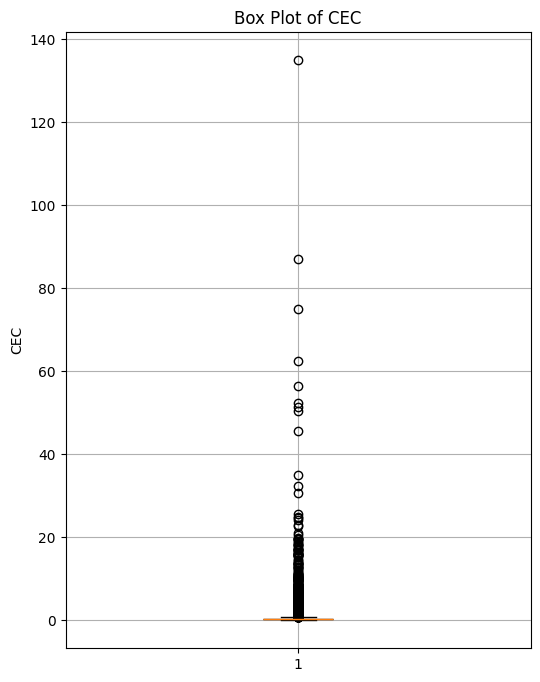

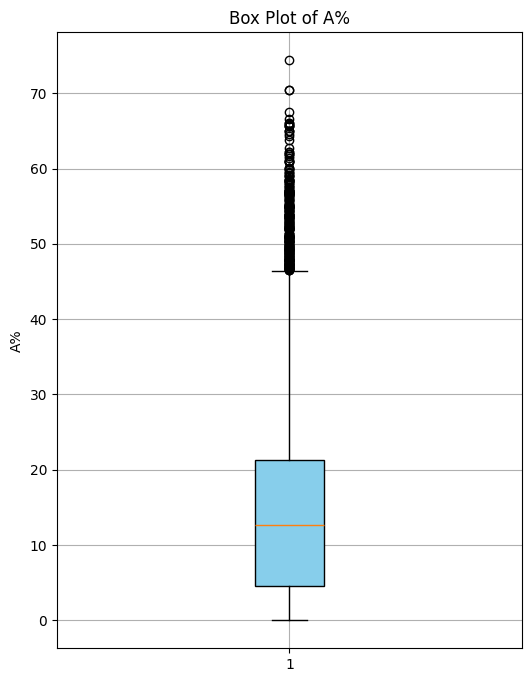

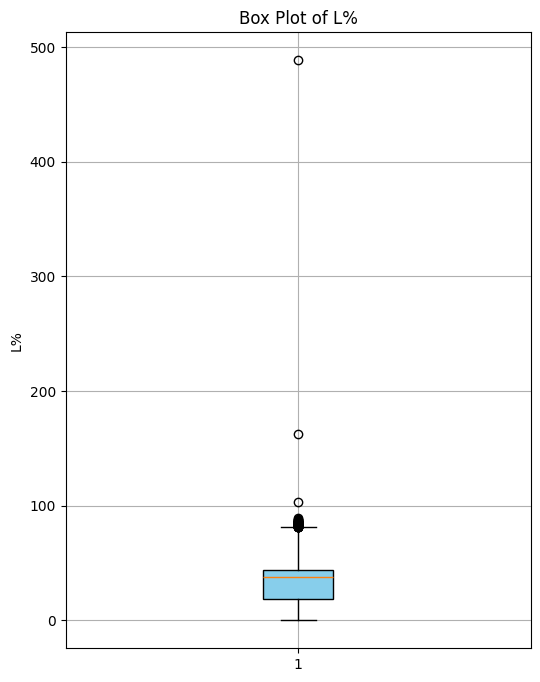

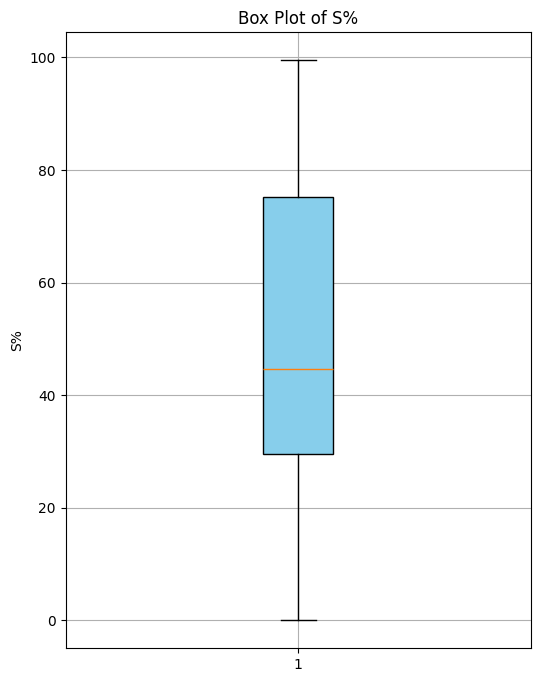

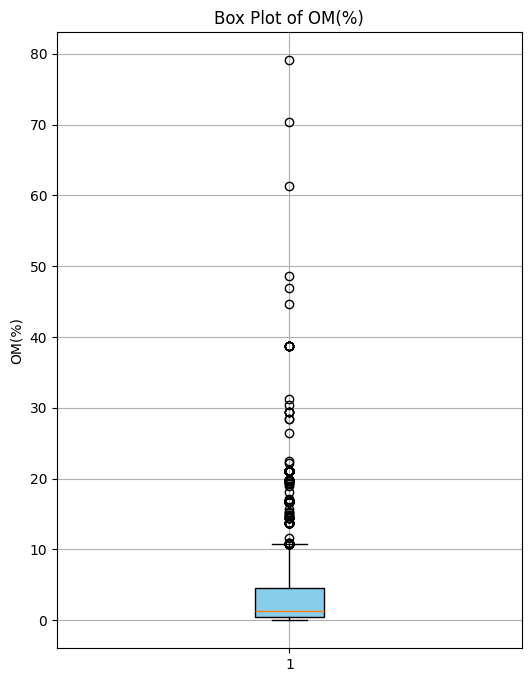

In [45]:
for i in merged_df.columns[4:]:
    plt.figure(figsize=(6, 8))
    plt.boxplot(merged_df[i].dropna(), vert=True, patch_artist=True, boxprops=dict(facecolor='skyblue'))

    plt.ylabel(i)
    plt.title(f'Box Plot of {i}')

    # Show the plot
    plt.grid(True)
    plt.show()

In [46]:
merged_df.to_csv("../../results/Soil/full_splined_NAN2.csv")

In [47]:
uniques = merged_df.drop_duplicates(subset=["X","Y"])
uniques

,SID,X,Y,UD,LD,pH,CE,CEC,A%,L%,S%,OM(%)
0,-0.0002541362021_35.83417876,-0.000254,35.834179,0.0,30.0,7.581977,3.176410,0.320644,3.874832,16.714290,79.410878,0.505885
2,-0.0003898600894_35.83778028,-0.000390,35.837780,0.0,30.0,7.206384,3.948343,0.271090,3.668154,25.163273,71.168573,0.589162
4,-0.003494819662_35.81572507,-0.003495,35.815725,0.0,30.0,7.770263,1.677930,0.317694,0.980614,12.372019,86.647367,0.468296
6,-0.003630258252_35.81212353,-0.003630,35.812124,0.0,30.0,8.049828,3.836355,0.320034,5.316877,14.397284,80.285839,0.505885
8,-0.003765672812_35.80852198,-0.003766,35.808522,0.0,30.0,7.499265,4.608883,0.322710,3.284772,162.925590,71.125719,0.501272
...,...,...,...,...,...,...,...,...,...,...,...,...
4304,7.809722222_36.78055556,7.809722,36.780556,0.0,30.0,8.270000,274.000000,0.250000,48.000000,24.400000,22.050000,1.585741
4306,7.9925_36.84861111,7.992500,36.848611,0.0,30.0,5.598996,19.860000,0.119979,4.620103,27.112725,68.267171,79.074556
4308,8.2_36.9,8.200000,36.900000,0.0,30.0,5.451622,47.800000,0.099874,3.893451,40.802534,55.304015,61.363843
4310,8.341388889_36.90027778,8.341389,36.900278,0.0,30.0,6.221084,21.764061,0.100000,6.147587,25.219737,68.632676,22.523778


In [ ]:
df=merged_df